# Titanic: regole decisionali, decision set/list e sequential covering

Notebook di accompagnamento alla nota `appunti/approfondimenti/decision_rules_approfondimento.md` del cookbook (lezione del 6 marzo 2026, seconda parte, e anticipo dell'11 marzo). Tutto passa per il modulo didattico `rule_learning.py`, scritto a mano con numpy e pandas per rendere visibile ogni passaggio:

| Oggetto | Che cosa fa |
|---|---|
| `Condition` | un letterale: `x ≤ t`, `x > t`, `x = v`, `x ≠ v`, `x ∈ S`, `x mancante` |
| `Rule` | congiunzione (AND) di condizioni + classe predetta |
| `rule_stats` | supporto, accuratezza, baseline, lift, Laplace, intervallo di Wilson |
| `DecisionSet` | regole senza ordine: voto (semplice o pesato) + default |
| `DecisionList` | prima regola soddisfatta + default; regioni effettive $E_j$; spiegazione locale |
| `learn_one_rule`, `sequential_covering` | separate-and-conquer top-down greedy (ricetta di Molnar) |

**Politica sui mancanti, dichiarata una volta per tutte:** un letterale come `Age ≤ 30` è **falso** se l'età manca; per parlare dei mancanti esiste il letterale esplicito `Age mancante`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from itertools import combinations, permutations
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from rule_learning import (Condition, Rule, DecisionList, DecisionSet, rule_stats, rules_table,
                           candidate_conditions, learn_one_rule, sequential_covering, coverage_matrix)
from tree_plots import DIED, SURVIVED

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("../data/titanic.csv")
title = df["Name"].str.extract(r",\s*([^.]+)\.")[0].str.strip()
df["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Other")
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

types = {"Sex": "nominal", "Pclass": "ordered", "Age": "ordered", "Title": "nominal",
         "FamilySize": "ordered", "Fare": "ordered", "Embarked": "nominal"}
X, y = df[list(types)], df["Survived"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
print(f"training {len(Xtr)} (sopravvissuti {ytr.mean():.3f}), test {len(Xte)} (sopravvissuti {yte.mean():.3f})")
print("mancanti nel training:", Xtr.isna().sum()[Xtr.isna().sum() > 0].to_dict())

training 623 (sopravvissuti 0.384), test 268 (sopravvissuti 0.384)
mancanti nel training: {'Age': 127, 'Embarked': 2}


## 0. Il dataset: Titanic

891 passeggeri (copia Data Science Dojo / training set Kaggle), una riga per persona; **target** `Survived` (1 = sopravvissuto). Delle 12 colonne originali si usano:

| Feature | Significato | Tipo | Note |
|---|---|---|---|
| `Sex` | female / male | nominale binaria | la più informativa da sola |
| `Pclass` | classe del biglietto 1/2/3 | ordinale | tasso monotono decrescente |
| `Age` | età in anni | continua | 177 mancanti, informativi |
| `Title` | titolo estratto da `Name` (Mr, Mrs, Miss, Master, Other) | nominale derivata | codifica sesso **ed** età |
| `FamilySize` | `SibSp + Parch + 1` | conteggio | relazione a gobba |
| `Fare` | tariffa del biglietto | continua | asimmetrica, 15 valori a 0 |
| `Embarked` | porto: C, Q, S | nominale | 2 mancanti; proxy della classe |

Escluse: `PassengerId` (identificativo), `Name` (sostituita da `Title`), `Ticket` (681 valori), `Cabin` (77% mancante), `SibSp`/`Parch` (confluite in `FamilySize`).

In [2]:
print(f"passeggeri: {len(df)}, sopravvissuti: {df.Survived.sum()} ({df.Survived.mean():.3f})")
print("Titoli originali:", title.value_counts().to_dict())
for c in ["Sex", "Pclass", "Title", "Embarked", "FamilySize"]:
    t = df.groupby(c, dropna=False)["Survived"].agg(passeggeri="count", sopravvissuti="sum", tasso="mean").round(3)
    display(t.T)
age_band = pd.cut(df.Age, [0, 16.71, 30, 45, 100]).cat.add_categories("mancante").fillna("mancante")
fare_band = pd.cut(df.Fare, [-1, 7.75, 12.48, 27.9, 61.46, 600])
display(df.groupby(age_band, observed=True)["Survived"].agg(passeggeri="count", tasso="mean").round(3).T)
display(df.groupby(fare_band, observed=True)["Survived"].agg(passeggeri="count", tasso="mean").round(3).T)
print("Age:", df.Age.describe().round(2).to_dict())
print("Fare:", df.Fare.describe().round(2).to_dict(), "| tariffe a zero:", int((df.Fare == 0).sum()))

passeggeri: 891, sopravvissuti: 342 (0.384)
Titoli originali: {'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Dr': 7, 'Rev': 6, 'Major': 2, 'Mlle': 2, 'Col': 2, 'Don': 1, 'Mme': 1, 'Ms': 1, 'Lady': 1, 'Sir': 1, 'Capt': 1, 'the Countess': 1, 'Jonkheer': 1}


Sex,female,male
passeggeri,314.000,577.000
sopravvissuti,233.000,109.000
tasso,0.742,0.189


Pclass,1,2,3
passeggeri,216.00,184.000,491.000
sopravvissuti,136.00,87.000,119.000
tasso,0.63,0.473,0.242


Title,Master,Miss,Mr,Mrs,Other
passeggeri,40.000,182.000,517.000,125.000,27.000
sopravvissuti,23.000,127.000,81.000,99.000,12.000
tasso,0.575,0.698,0.157,0.792,0.444


Embarked,C,Q,S,NaN
passeggeri,168.000,77.00,644.000,2.0
sopravvissuti,93.000,30.00,217.000,2.0
tasso,0.554,0.39,0.337,1.0


FamilySize,1,2,3,4,5,6,7,8,11
passeggeri,537.000,161.000,102.000,29.000,15.0,22.000,12.000,6.0,7.0
sopravvissuti,163.000,89.000,59.000,21.000,3.0,3.000,4.000,0.0,0.0
tasso,0.304,0.553,0.578,0.724,0.2,0.136,0.333,0.0,0.0


Age,"(0.0, 16.71]","(16.71, 30.0]","(30.0, 45.0]","(45.0, 100.0]",mancante
passeggeri,100.00,309.000,202.000,103.000,177.000
tasso,0.55,0.359,0.426,0.369,0.294


Fare,"(-1.0, 7.75]","(7.75, 12.48]","(12.48, 27.9]","(27.9, 61.46]","(61.46, 600.0]"
passeggeri,140.000,243.000,256.000,132.00,120.000
tasso,0.207,0.247,0.426,0.47,0.683


Age: {'count': 714.0, 'mean': 29.7, 'std': 14.53, 'min': 0.42, '25%': 20.12, '50%': 28.0, '75%': 38.0, 'max': 80.0}
Fare: {'count': 891.0, 'mean': 32.2, 'std': 49.69, 'min': 0.0, '25%': 7.91, '50%': 14.45, '75%': 31.0, 'max': 512.33} | tariffe a zero: 15


L'interazione **sesso × classe** anticipa quasi tutto il notebook: donne di 1ª–2ª classe oltre il 92%, donne di 3ª al 50% (il gruppo conteso dalle regole del §3), uomini di 2ª–3ª sotto il 16% (il default).

In [3]:
display(pd.crosstab(df.Sex, df.Pclass, values=df.Survived, aggfunc="mean").round(3))
display(pd.crosstab(df.Sex, df.Pclass))
display(pd.crosstab(df.Title, df.Sex))

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


Pclass,1,2,3
Sex,,,
female,94,76,144
male,122,108,347


Sex,female,male
Title,,
Master,0,40
Miss,182,0
Mr,0,517
Mrs,125,0
Other,7,20


## 1. Anatomia di una regola

Una regola è `IF antecedente THEN conseguente`. L'antecedente è un AND di **letterali**; la forma del letterale dipende dal tipo della feature, come per i test di un albero:

- ordinata (`Age`, `Pclass`, `Fare`, `FamilySize`): `x ≤ t` oppure `x > t`; più letterali sulla stessa feature si fondono in un intervallo;
- nominale (`Sex`, `Title`, `Embarked`): `x = v`, `x ≠ v` o `x ∈ S`.

Le soglie disponibili sono decise **prima** della ricerca (quantili del training): è la discretizzazione preliminare tipica degli algoritmi di regole.

In [4]:
cands = candidate_conditions(Xtr, types)
print(len(cands), "letterali candidati")
pd.DataFrame({"feature": [c.feature for c in cands], "letterale": [str(c) for c in cands]}) \
  .groupby("feature", sort=False)["letterale"].apply(lambda s: " | ".join(s)).to_frame()

54 letterali candidati


,letterale
feature,
Sex,Sex = female | Sex = male
Pclass,Pclass ≤ 1.5 | Pclass > 1.5 | Pclass ≤ 2.5 | Pclass > 2.5
Age,Age ≤ 16.71 | Age > 16.71 | Age ≤ 21 | Age > 21 | Age ≤ 26 | Age > 26 | Age ≤ 30 | Age...
Title,Title = Master | Title ≠ Master | Title = Miss | Title ≠ Miss | Title = Mr | Title ≠ M...
FamilySize,FamilySize ≤ 1 | FamilySize > 1 | FamilySize ≤ 2 | FamilySize > 2 | FamilySize ≤ 3 | F...
Fare,Fare ≤ 7.75 | Fare > 7.75 | Fare ≤ 8.05 | Fare > 8.05 | Fare ≤ 12.48 | Fare > 12.48 | ...
Embarked,Embarked = C | Embarked ≠ C | Embarked = Q | Embarked ≠ Q | Embarked = S | Embarked ≠ ...


Fusione dei letterali sulla stessa feature (solo nella stampa: la semantica resta l'AND):

In [5]:
r = Rule((Condition("Age", ">", 16.71), Condition("Age", "<=", 36), Condition("Title", "!=", "Mr"),
          Condition("Title", "!=", "Other"), Condition("Pclass", "<=", 2.5)), 1)
print(r)

IF 16.71 < Age ≤ 36 AND Title ∉ {Mr, Other} AND Pclass ≤ 2.5 THEN y = 1


### 1.1 Il mancante non è né vero né falso

Elena (prima classe, età mancante) e la regola `Age ≤ 30 → sopravvive`. Con la politica dichiarata la regola **tace**; il letterale `Age mancante` invece si attiva.

In [6]:
elena = pd.DataFrame([{"Sex": "female", "Pclass": 1, "Age": np.nan, "Title": "Mrs",
                       "FamilySize": 1, "Fare": 80.0, "Embarked": "S"}])
for c in [Condition("Age", "<=", 30), Condition("Age", ">", 30), Condition("Age", "missing")]:
    print(f"{str(c):14s} → {bool(c.mask(elena)[0])}")

Age ≤ 30       → False
Age > 30       → False
Age mancante   → True


## 2. Le misure di una regola

- **supporto** = coperti / tutti: basta l'antecedente;
- **accuratezza** = coperti corretti / coperti: serve il conseguente;
- **baseline** = frequenza della classe predetta: il riferimento per dire se l'accuratezza è «buona»; **lift** = accuratezza / baseline;
- **Laplace** $=(c+1)/(n+2)$: accuratezza «prudente», che penalizza le regole con pochi casi;
- **intervallo di Wilson** al 95%: incertezza dell'accuratezza dovuta alla numerosità;
- **recall della classe**: quota dei sopravvissuti catturati dalla regola.

### 2.1 Specializzare una regola

In [7]:
r1 = Rule((Condition("Sex", "==", "female"),), 1, "r1")
r2 = Rule(r1.conditions + (Condition("Pclass", "<=", 2.5),), 1, "r2")
r3 = Rule(r2.conditions + (Condition("Age", "<=", 30),), 1, "r3")
cols = ["regola", "antecedente", "coperti", "corretti", "supporto", "accuratezza", "baseline", "lift",
        "laplace", "wilson_lo", "wilson_hi", "recall_classe"]
print("TRAINING"); display(rules_table([r1, r2, r3], Xtr, ytr)[cols].round(3))
print("TEST");     display(rules_table([r1, r2, r3], Xte, yte)[cols].round(3))

TRAINING


,regola,antecedente,coperti,corretti,supporto,accuratezza,baseline,lift,laplace,wilson_lo,wilson_hi,recall_classe
0,r1,Sex = female,219,162,0.352,0.740,0.384,1.928,0.738,0.678,0.793,0.678
1,r2,Sex = female AND Pclass ≤ 2.5,123,116,0.197,0.943,0.384,2.458,0.936,0.887,0.972,0.485
2,r3,Sex = female AND Pclass ≤ 2.5 AND Age ≤ 30,57,54,0.091,0.947,0.384,2.470,0.932,0.856,0.982,0.226


TEST


,regola,antecedente,coperti,corretti,supporto,accuratezza,baseline,lift,laplace,wilson_lo,wilson_hi,recall_classe
0,r1,Sex = female,95,71,0.354,0.747,0.384,1.945,0.742,0.652,0.824,0.689
1,r2,Sex = female AND Pclass ≤ 2.5,47,45,0.175,0.957,0.384,2.491,0.939,0.858,0.988,0.437
2,r3,Sex = female AND Pclass ≤ 2.5 AND Age ≤ 30,22,20,0.082,0.909,0.384,2.365,0.875,0.722,0.975,0.194


Il supporto scende a ogni AND (è garantito); l'accuratezza sale molto da `r1` a `r2` e poi quasi non si muove. `r3` dimezza supporto e recall per un guadagno di accuratezza trascurabile: Laplace la giudica **peggiore** di `r2`.

### 2.2 Il compromesso supporto–accuratezza su tutte le regole brevi

Tutte le regole con 1 o 2 letterali che predicono «sopravvive» (coperti ≥ 1), sul training.

   regole  supporto_medio  accuratezza_media
k                                           
1      54           0.462              0.429
2    1159           0.222              0.452


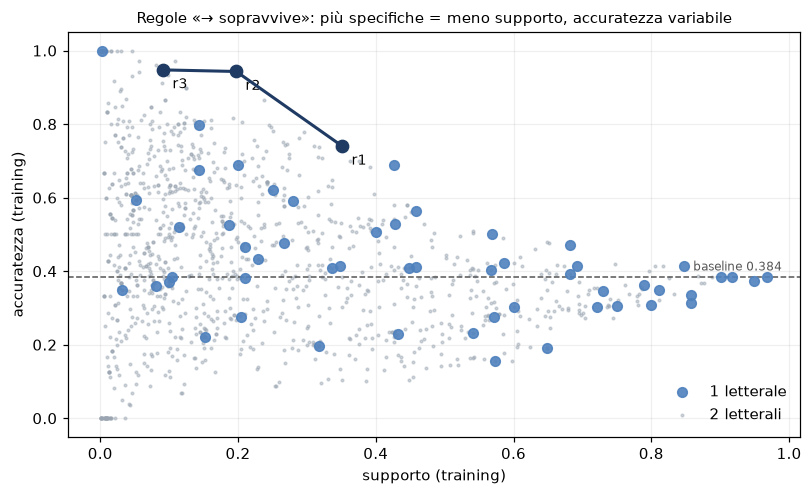

In [8]:
masks = {c: c.mask(Xtr) for c in cands}
yv = ytr.to_numpy()
rows = []
for k in (1, 2):
    for combo in combinations(cands, k):
        if k == 2 and combo[0].feature == combo[1].feature:
            continue
        m = np.logical_and.reduce([masks[c] for c in combo])
        n = int(m.sum())
        if n:
            rows.append({"k": k, "rule": " AND ".join(map(str, combo)), "coperti": n,
                         "supporto": n / len(yv), "accuratezza": yv[m].mean()})
short = pd.DataFrame(rows)
print(short.groupby("k").agg(regole=("rule", "size"), supporto_medio=("supporto", "mean"),
                             accuratezza_media=("accuratezza", "mean")).round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for k, mk, col in ((1, "o", "#4f81bd"), (2, ".", "#9aa5b1")):
    s = short[short.k == k]
    ax.scatter(s.supporto, s.accuratezza, marker=mk, s=40 if k == 1 else 12, alpha=0.9 if k == 1 else 0.45,
               color=col, label="1 letterale" if k == 1 else "2 letterali", zorder=3 if k == 1 else 2)
ax.axhline(ytr.mean(), color="#555", lw=1, ls="--")
ax.text(0.99, ytr.mean() + 0.01, f"baseline {ytr.mean():.3f}", ha="right", va="bottom", fontsize=8, color="#555")
chain = rules_table([r1, r2, r3], Xtr, ytr)
ax.plot(chain.supporto, chain.accuratezza, "-o", color="#1f3b63", lw=2, ms=8, zorder=4)
for _, rw in chain.iterrows():
    ax.annotate(rw["regola"], (rw.supporto, rw.accuratezza), xytext=(6, -12), textcoords="offset points", fontsize=9)
ax.set_xlabel("supporto (training)"); ax.set_ylabel("accuratezza (training)")
ax.set_title("Regole «→ sopravvive»: più specifiche = meno supporto, accuratezza variabile", fontsize=10)
ax.legend(frameon=False, loc="lower right"); ax.grid(alpha=0.2)
fig.tight_layout(); plt.show()

I punti a destra hanno supporto alto e accuratezza vicina alla baseline (una regola che coprisse tutti avrebbe esattamente l'accuratezza della baseline); salire verso l'alto richiede di stringere. Il bordo superiore della nuvola è la **frontiera** del compromesso.

### 2.3 Regole perfette su pochi casi

Fra le regole con 2 o 3 letterali su feature diverse, quelle con accuratezza 100% sul training che coprono da 3 a 6 casi. Come si comportano sul test?

In [9]:
masks_te = {c: c.mask(Xte) for c in cands}
yte_v = yte.to_numpy()
pure = []
for k in (2, 3):
    for combo in combinations(cands, k):
        if len({c.feature for c in combo}) < k:
            continue
        m = np.logical_and.reduce([masks[c] for c in combo]); n = int(m.sum())
        if 3 <= n <= 6 and yv[m].all():
            mt = np.logical_and.reduce([masks_te[c] for c in combo])
            pure.append({"k": k, "coperti_train": n, "coperti_test": int(mt.sum()),
                         "corretti_test": int(yte_v[mt].sum())})
pure = pd.DataFrame(pure)
tot_c, tot_n = pure.corretti_test.sum(), pure.coperti_test.sum()
print(f"regole pure su 3-6 casi di training: {len(pure)}")
print(f"di queste, {(pure.coperti_test == 0).mean():.1%} non copre nessun caso di test")
print(f"accuratezza sul test (casi coperti cumulati): {tot_c}/{tot_n} = {tot_c / tot_n:.3f}")

regole pure su 3-6 casi di training: 200
di queste, 28.0% non copre nessun caso di test
accuratezza sul test (casi coperti cumulati): 255/309 = 0.825


Il 100% di training non si conserva: è lo stesso fenomeno delle foglie piccole di un albero profondo. Per questo i learner di regole impongono un minimo di copertura o usano misure come Laplace.

## 3. Più regole: conflitti e casi scoperti

Tre regole scritte a mano, deliberatamente sovrapposte:

In [10]:
RA = Rule((Condition("Sex", "==", "female"),), 1, "RA")
RB = Rule((Condition("Pclass", ">", 2.5),), 0, "RB")
RC = Rule((Condition("Title", "==", "Master"),), 1, "RC")
rules3 = [RA, RB, RC]
for r in rules3: print(r)
stats3 = rules_table(rules3, Xtr, ytr)
display(stats3[["regola", "predice", "coperti", "corretti", "supporto", "accuratezza"]].round(3))
C = coverage_matrix(rules3, Xtr)
print("regole attive per caso:", pd.Series(C.sum(axis=1)).value_counts().sort_index().to_dict())

RA: IF Sex = female THEN y = 1
RB: IF Pclass > 2.5 THEN y = 0
RC: IF Title = Master THEN y = 1


,regola,predice,coperti,corretti,supporto,accuratezza
0,RA,1,219,162,0.352,0.740
1,RB,0,337,259,0.541,0.769
2,RC,1,32,19,0.051,0.594


regole attive per caso: {0: 153, 1: 352, 2: 118}


### 3.1 Decision set: la politica di voto fa parte del modello

Stesse regole, quattro politiche; nessuna regola attiva → default 0 in tutti i casi.

In [11]:
sets = {"voto semplice, parità → 0": DecisionSet(rules3, 0, tie_class=0),
        "voto semplice, parità → 1": DecisionSet(rules3, 0, tie_class=1),
        "pesato per supporto": DecisionSet(rules3, 0, list(stats3.supporto)),
        "pesato per accuratezza": DecisionSet(rules3, 0, list(stats3.accuratezza))}
_, status = sets["voto semplice, parità → 0"].predict_with_status(Xtr)
print(pd.Series(status).value_counts().to_string(), "\n")
res = []
for name, s in sets.items():
    res.append({"politica": name, "acc. training": (s.predict(Xtr) == ytr).mean(),
                "acc. test": (s.predict(Xte) == yte).mean()})
display(pd.DataFrame(res).round(3))

donna3 = ((Xtr.Sex == "female") & (Xtr.Pclass == 3)).to_numpy()
print(f"donne di terza classe nel training: {donna3.sum()}, sopravvissute {ytr[donna3].mean():.3f}")
for name, s in sets.items():
    print(f"  {name:28s} → donne 3ª classe: {sorted(int(v) for v in set(s.predict(Xtr[donna3])))}")
master3 = ((Xtr.Title == "Master") & (Xtr.Pclass == 3)).to_numpy()
print(f"Master di terza classe nel training: {master3.sum()}, sopravvissuti {ytr[master3].mean():.3f}")
for name, s in sets.items():
    print(f"  {name:28s} → Master 3ª classe: {sorted(int(v) for v in set(s.predict(Xtr[master3])))}")

una regola           352
default              153
conflitto: parità    118 



,politica,acc. training,acc. test
0,"voto semplice, parità → 0",0.807,0.784
1,"voto semplice, parità → 1",0.795,0.791
2,pesato per supporto,0.807,0.784
3,pesato per accuratezza,0.807,0.784


donne di terza classe nel training: 96, sopravvissute 0.479
  voto semplice, parità → 0    → donne 3ª classe: [0]
  voto semplice, parità → 1    → donne 3ª classe: [1]
  pesato per supporto          → donne 3ª classe: [0]
  pesato per accuratezza       → donne 3ª classe: [0]
Master di terza classe nel training: 22, sopravvissuti 0.409
  voto semplice, parità → 0    → Master 3ª classe: [0]
  voto semplice, parità → 1    → Master 3ª classe: [1]
  pesato per supporto          → Master 3ª classe: [0]
  pesato per accuratezza       → Master 3ª classe: [0]


### 3.2 Decision list: l'ordine fa parte del modello

In [12]:
rows, preds = [], {}
for perm in permutations(rules3):
    dl = DecisionList(list(perm), 0)
    key = " → ".join(r.name for r in perm)
    preds[key] = dl.predict(Xtr)
    rows.append({"ordine": key, "acc. training": (preds[key] == ytr).mean(),
                 "acc. test": (dl.predict(Xte) == yte).mean()})
display(pd.DataFrame(rows).round(3))
a, b = preds["RA → RB → RC"], preds["RB → RA → RC"]
print(f"RA→RB→RC vs RB→RA→RC: decisioni diverse su {(a != b).sum()} passeggeri di training "
      f"(di cui donne di terza classe: {((a != b) & donna3).sum()})")

,ordine,acc. training,acc. test
0,RA → RB → RC,0.801,0.799
1,RA → RC → RB,0.795,0.791
2,RB → RA → RC,0.807,0.784
3,RB → RC → RA,0.807,0.784
4,RC → RA → RB,0.795,0.791
5,RC → RB → RA,0.801,0.776


RA→RB→RC vs RB→RA→RC: decisioni diverse su 96 passeggeri di training (di cui donne di terza classe: 96)


In [13]:
dl = DecisionList([RB, RA, RC], 0)
print(dl, "\n")
display(dl.regions(Xtr, ytr).round(3))

IF Pclass > 2.5 THEN y = 0
ELSE IF Sex = female THEN y = 1
ELSE IF Title = Master THEN y = 1
ELSE y = 0 



,posizione,regola,copre (da sola),decide (E_j),corretti,acc. effettiva
0,1,IF Pclass > 2.5 THEN y = 0,337,337,259,0.769
1,2,IF Sex = female THEN y = 1,219,123,116,0.943
2,3,IF Title = Master THEN y = 1,32,10,10,1.000
3,default,ELSE,153,153,118,0.771


Nell'ordine `RB → RA → RC` la regola `RC` decide solo per i «Master» **non** di terza classe: la sua regione effettiva $E_3 = \{\neg a_{RB} \wedge \neg a_{RA} \wedge a_{RC}\}$ è molto più piccola dell'antecedente. Leggere `RC` da sola fraintende il modello.

## 4. Una nota sulla linearità (lavagna 2)

La lavagna disegna due feature $A_1, A_2$, due soglie $\tau$ e $\sigma$ e tre regioni: 1 = $A_1 \le \tau$ (negativa), 2 = $A_1 > \tau \wedge A_2 \le \sigma$ (positiva), 3 = $A_1 > \tau \wedge A_2 > \sigma$ (negativa). L'albero corrispondente testa $A_1$ e poi $A_2$. La classe positiva è un angolo: il confine è una **spezzata**, non una retta. Alberi e regole sono modelli **non lineari**.

positivi: 0.298 (baseline 'sempre negativo' 0.702)
lista con una regola: accuratezza 1.000
regressione logistica (confine lineare): accuratezza 0.913


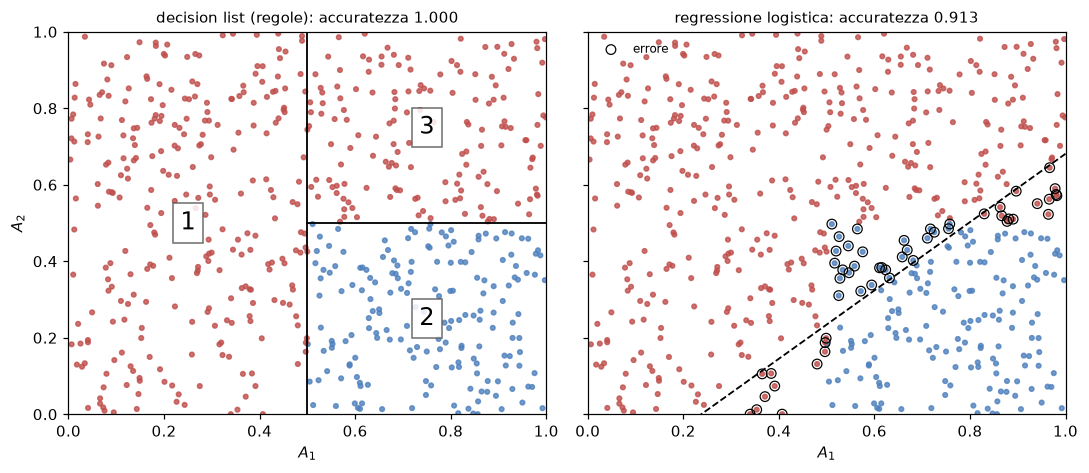

In [14]:
rng = np.random.default_rng(0)
tau, sigma = 0.5, 0.5
G = pd.DataFrame(rng.uniform(0, 1, size=(600, 2)), columns=["A1", "A2"])
g = ((G.A1 > tau) & (G.A2 <= sigma)).astype(int).to_numpy()
corner = DecisionList([Rule((Condition("A1", ">", tau), Condition("A2", "<=", sigma)), 1)], 0)
logit = LogisticRegression(C=1e4, max_iter=1000).fit(G, g)
print(f"positivi: {g.mean():.3f} (baseline 'sempre negativo' {1 - g.mean():.3f})")
print(f"lista con una regola: accuratezza {(corner.predict(G) == g).mean():.3f}")
print(f"regressione logistica (confine lineare): accuratezza {logit.score(G, g):.3f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for ax, (name, pred) in zip(axs, (("decision list (regole)", corner.predict(G)),
                                  ("regressione logistica", logit.predict(G)))):
    ax.scatter(G.A1, G.A2, s=9, c=np.where(g == 1, SURVIVED, DIED), alpha=0.8)
    wrong = pred != g
    ax.scatter(G.A1[wrong], G.A2[wrong], s=40, facecolors="none", edgecolors="k", lw=0.8, label="errore")
    ax.set_title(f"{name}: accuratezza {(pred == g).mean():.3f}", fontsize=10)
    ax.set_xlabel("$A_1$"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axs[0].set_ylabel("$A_2$")
axs[0].plot([tau, tau], [0, 1], "k-", lw=1.2); axs[0].plot([tau, 1], [sigma, sigma], "k-", lw=1.2)
for (x0, y0, lab) in ((0.25, 0.5, "1"), (0.75, 0.25, "2"), (0.75, 0.75, "3")):
    axs[0].text(x0, y0, lab, fontsize=16, ha="center", va="center",
                bbox=dict(boxstyle="square", fc="white", ec="#555", alpha=0.85))
xx = np.linspace(0, 1, 50)
w, b0 = logit.coef_[0], logit.intercept_[0]
axs[1].plot(xx, -(w[0] * xx + b0) / w[1], "k--", lw=1.2)
axs[1].legend(frameon=False, loc="upper left", fontsize=8)
fig.tight_layout(); plt.show()

Pallini blu = positivi (regione 2), rossi = negativi; i cerchi neri sono gli errori. Una regola con due letterali descrive esattamente l'angolo; una retta deve tagliare male una parte dell'angolo o della «L» negativa.

## 5. Sequential covering

Ricetta (Molnar): impara una regola per la classe positiva sul **residuo**, aggiungila alla lista, **rimuovi tutti i casi coperti** (corretti o no), ripeti; alla fine un default = classe più frequente fra i non coperti.

La regola singola si cerca top-down: si parte da `IF vero` e si aggiunge il letterale migliore finché il punteggio migliora (massimo 3 letterali, almeno 10 casi coperti). Il punteggio decide **che tipo** di regole si trovano.

### 5.1 La ricerca di una regola, passo per passo

In [15]:
for crit in ("accuracy", "laplace", "foil"):
    best, trace = learn_one_rule(Xtr, ytr, 1, cands, criterion=crit, min_covered=10, return_trace=True)
    print(f"--- criterio {crit}: regola scelta → {best.antecedent()}")
    display(pd.DataFrame([vars(t) for t in trace]).round(3))

--- criterio accuracy: regola scelta → Title = Mrs AND Pclass ≤ 1.5


,passo,regola,coperti,positivi,accuratezza,punteggio
0,1,Title = Mrs,89,71,0.798,0.798
1,2,Title = Mrs AND Pclass ≤ 1.5,29,29,1.000,1.000
2,3,Title = Mrs AND Pclass ≤ 1.5 AND Embarked ≠ Q,28,28,1.000,1.000


--- criterio laplace: regola scelta → Title = Mrs AND Pclass ≤ 1.5


,passo,regola,coperti,positivi,accuratezza,punteggio
0,1,Title = Mrs,89,71,0.798,0.791
1,2,Title = Mrs AND Pclass ≤ 1.5,29,29,1.000,0.968
2,3,Title = Mrs AND Pclass ≤ 1.5 AND Embarked ≠ Q,28,28,1.000,0.967


--- criterio foil: regola scelta → Title ∉ {Mr, Other} AND Pclass ≤ 2.5


,passo,regola,coperti,positivi,accuratezza,punteggio
0,1,Title ≠ Mr,266,183,0.688,154.203
1,2,Title ≠ Mr AND Pclass ≤ 2.5,148,128,0.865,42.257
2,3,"Title ∉ {Mr, Other} AND Pclass ≤ 2.5",128,121,0.945,15.526


FOIL (Quinlan) pesa il guadagno di precisione per il **numero di positivi** che restano coperti: $\text{FOIL} = p_1\left(\log_2\frac{p_1}{p_1+n_1}-\log_2\frac{p_0}{p_0+n_0}\right)$. Accuratezza e Laplace guardano solo la purezza e, con `min_covered=10`, inseguono piccoli gruppi quasi puri.

### 5.2 Il ciclo esterno

In [16]:
sc, trace = sequential_covering(Xtr, ytr, 1, candidates=cands, criterion="foil", min_covered=10,
                                min_accuracy=0.6, return_trace=True)
display(trace.round(3))
print(sc)
print(f"\naccuratezza: training {(sc.predict(Xtr) == ytr).mean():.3f}, test {(sc.predict(Xte) == yte).mean():.3f}")

,passo,regola,residuo_prima,coperti,corretti,accuratezza,residuo_dopo
0,1,"Title ∉ {Mr, Other} AND Pclass ≤ 2.5",623,128,121,0.945,495
1,2,Title ≠ Mr AND Fare ≤ 19.36 AND Embarked ≠ S,495,39,26,0.667,456
2,3,Sex = female AND FamilySize ≤ 2 AND Fare > 12.48,456,11,9,0.818,445


IF Title ∉ {Mr, Other} AND Pclass ≤ 2.5 THEN y = 1
ELSE IF Title ≠ Mr AND Fare ≤ 19.36 AND Embarked ≠ S THEN y = 1
ELSE IF Sex = female AND FamilySize ≤ 2 AND Fare > 12.48 THEN y = 1
ELSE y = 0

accuratezza: training 0.831, test 0.813


In [17]:
print("Regioni effettive sul TRAINING"); display(sc.regions(Xtr, ytr).round(3))
print("Regioni effettive sul TEST");     display(sc.regions(Xte, yte).round(3))

Regioni effettive sul TRAINING


,posizione,regola,copre (da sola),decide (E_j),corretti,acc. effettiva
0,1,"IF Title ∉ {Mr, Other} AND Pclass ≤ 2.5 THEN y = 1",128,128,121,0.945
1,2,IF Title ≠ Mr AND Fare ≤ 19.36 AND Embarked ≠ S THEN y = 1,42,39,26,0.667
2,3,IF Sex = female AND FamilySize ≤ 2 AND Fare > 12.48 THEN y = 1,93,11,9,0.818
3,default,ELSE,445,445,362,0.813


Regioni effettive sul TEST


,posizione,regola,copre (da sola),decide (E_j),corretti,acc. effettiva
0,1,"IF Title ∉ {Mr, Other} AND Pclass ≤ 2.5 THEN y = 1",47,47,45,0.957
1,2,IF Title ≠ Mr AND Fare ≤ 19.36 AND Embarked ≠ S THEN y = 1,19,17,13,0.765
2,3,IF Sex = female AND FamilySize ≤ 2 AND Fare > 12.48 THEN y = 1,40,5,3,0.600
3,default,ELSE,199,199,157,0.789


### 5.3 Il criterio cambia il modello

In [18]:
rows = []
for crit in ("accuracy", "laplace", "foil"):
    for mc in (5, 10, 20):
        m = sequential_covering(Xtr, ytr, 1, candidates=cands, criterion=crit, min_covered=mc)
        rows.append({"modello": f"covering {crit}, min_covered={mc}", "regole": len(m.rules),
                     "letterali": sum(r.length for r in m.rules),
                     "acc. training": (m.predict(Xtr) == ytr).mean(), "acc. test": (m.predict(Xte) == yte).mean()})
fill = {"Age": Xtr.Age.median()}
Xtr_d = pd.get_dummies(Xtr.fillna(fill))
Xte_d = pd.get_dummies(Xte.fillna(fill)).reindex(columns=Xtr_d.columns, fill_value=False)
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtr_d, ytr)
rows.append({"modello": "baseline: sempre 0", "regole": 0, "letterali": 0,
             "acc. training": (ytr == 0).mean(), "acc. test": (yte == 0).mean()})
rows.append({"modello": "albero sklearn, profondità 3 (foglie)", "regole": tree.get_n_leaves(), "letterali": np.nan,
             "acc. training": tree.score(Xtr_d, ytr), "acc. test": tree.score(Xte_d, yte)})
pd.DataFrame(rows).round(3)

,modello,regole,letterali,acc. training,acc. test
0,"covering accuracy, min_covered=5",10,27.0,0.814,0.784
1,"covering accuracy, min_covered=10",10,27.0,0.838,0.810
2,"covering accuracy, min_covered=20",8,21.0,0.828,0.784
3,"covering laplace, min_covered=5",10,27.0,0.839,0.799
4,"covering laplace, min_covered=10",7,19.0,0.830,0.787
5,"covering laplace, min_covered=20",5,14.0,0.801,0.765
6,"covering foil, min_covered=5",3,9.0,0.831,0.813
7,"covering foil, min_covered=10",3,9.0,0.831,0.813
8,"covering foil, min_covered=20",3,9.0,0.831,0.806
9,baseline: sempre 0,0,0.0,0.616,0.616


Con accuratezza/Laplace si ottengono liste lunghe di regole molto specifiche; FOIL produce poche regole generali. Le differenze di test fra le righe valgono pochi casi su 268: vanno lette insieme alla variabilità fra split (§5.5).

### 5.4 Perché rimuovere **tutti** i coperti

Variante didattica: rimuovere solo i coperti **corretti**. Gli errori di `R1` restano nel residuo e le regole successive vengono apprese anche su di loro, ma in predizione quei casi sono ancora catturati da `R1`.

In [19]:
sc_c, tr_c = sequential_covering(Xtr, ytr, 1, candidates=cands, criterion="foil", min_covered=10,
                                 min_accuracy=0.6, remove="correct", return_trace=True)
display(tr_c.round(3))
print(sc_c, "\n")
reg = sc_c.regions(Xtr, ytr)
print("Che cosa decide davvero ciascuna regola (training):"); display(reg.round(3))
for j in range(1, len(sc_c.rules)):
    arrive = int((sc_c.fired(Xtr) >= j).sum())
    print(f"R{j+1}: appresa su {tr_c.residuo_prima[j]} casi, ma in predizione ne arrivano {arrive} "
          f"→ {tr_c.residuo_prima[j] - arrive} casi 'fantasma' già catturati da regole precedenti")
print(f"il default è stimato su {tr_c.residuo_dopo.iloc[-1]} casi, ne decide {int((sc_c.fired(Xtr) == len(sc_c.rules)).sum())}")

,passo,regola,residuo_prima,coperti,corretti,accuratezza,residuo_dopo
0,1,"Title ∉ {Mr, Other} AND Pclass ≤ 2.5",623,128,121,0.945,502
1,2,Title ≠ Mr AND Fare ≤ 19.36 AND Embarked ≠ S,502,39,26,0.667,476
2,3,Pclass ≤ 1.5 AND 21 < Age ≤ 36,476,25,15,0.600,461


IF Title ∉ {Mr, Other} AND Pclass ≤ 2.5 THEN y = 1
ELSE IF Title ≠ Mr AND Fare ≤ 19.36 AND Embarked ≠ S THEN y = 1
ELSE IF Pclass ≤ 1.5 AND 21 < Age ≤ 36 THEN y = 1
ELSE y = 0 

Che cosa decide davvero ciascuna regola (training):


,posizione,regola,copre (da sola),decide (E_j),corretti,acc. effettiva
0,1,"IF Title ∉ {Mr, Other} AND Pclass ≤ 2.5 THEN y = 1",128,128,121,0.945
1,2,IF Title ≠ Mr AND Fare ≤ 19.36 AND Embarked ≠ S THEN y = 1,42,39,26,0.667
2,3,IF Pclass ≤ 1.5 AND 21 < Age ≤ 36 THEN y = 1,47,25,15,0.600
3,default,ELSE,431,431,354,0.821


R2: appresa su 502 casi, ma in predizione ne arrivano 495 → 7 casi 'fantasma' già catturati da regole precedenti
R3: appresa su 476 casi, ma in predizione ne arrivano 456 → 20 casi 'fantasma' già catturati da regole precedenti
il default è stimato su 461 casi, ne decide 431


Il trace e il modello non raccontano più la stessa storia: le statistiche registrate durante l'apprendimento non sono quelle delle regioni effettive. Con la rimozione di tutti i coperti, invece, il residuo al passo $j$ coincide con i casi che arrivano alla regola $j$ nella lista: apprendimento e semantica sono allineati.

### 5.5 Stabilità su 30 split

In [20]:
rows, firsts = [], []
for seed in range(30):
    a_tr, a_te, b_tr, b_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
    cc = candidate_conditions(a_tr, types)
    m = sequential_covering(a_tr, b_tr, 1, candidates=cc, criterion="foil", min_covered=10)
    firsts.append(m.rules[0].antecedent())
    f = {"Age": a_tr.Age.median()}
    a_tr_d = pd.get_dummies(a_tr.fillna(f))
    a_te_d = pd.get_dummies(a_te.fillna(f)).reindex(columns=a_tr_d.columns, fill_value=False)
    t = DecisionTreeClassifier(max_depth=3, random_state=0).fit(a_tr_d, b_tr)
    rows.append({"covering FOIL": (m.predict(a_te) == b_te).mean(), "albero prof. 3": t.score(a_te_d, b_te),
                 "sempre 0": (b_te == 0).mean(), "n. regole": len(m.rules)})
st = pd.DataFrame(rows)
display(st.agg(["mean", "std", "min", "max"]).round(3))
print("Prima regola appresa nei 30 split:")
print(pd.Series(firsts).value_counts().to_string())

,covering FOIL,albero prof. 3,sempre 0,n. regole
mean,0.818,0.819,0.616,4.367
std,0.016,0.021,0.000,1.402
min,0.784,0.765,0.616,2.000
max,0.847,0.854,0.616,9.000


Prima regola appresa nei 30 split:
Title ∉ {Mr, Other} AND Pclass ≤ 2.5                20
Sex = female AND Pclass ≤ 2.5 AND Fare > 29.12       2
Sex = female AND Pclass ≤ 2.5 AND Embarked ≠ S       1
Sex = female AND Pclass ≤ 2.5 AND FamilySize ≤ 2     1
Sex = female AND Pclass ≤ 2.5 AND FamilySize > 1     1
Sex = female AND Pclass ≤ 2.5 AND Age ≤ 36           1
Sex = female AND Pclass ≤ 2.5 AND Fare > 26.68       1
Sex = female AND Pclass ≤ 2.5 AND Fare > 56.93       1
Sex = female AND Pclass ≤ 2.5 AND Age > 26           1
Sex = female AND Pclass ≤ 2.5 AND Fare > 27.9        1


## 6. Spiegazione locale con una decision list

La spiegazione di una predizione è la regola usata **più la negazione di tutte le precedenti**: è questo il costo cognitivo delle liste.

In [21]:
f_te = sc.fired(Xte)
idx = [Xte.index[f_te == j][0] for j in range(len(sc.rules) + 1)]   # un caso per posizione
for i in idx:
    row = Xte.loc[[i]]
    print(row.to_dict("records")[0], " | sopravvissuto:", int(yte[i]))
    print("   ", sc.explain(row), "\n")

{'Sex': 'female', 'Pclass': 2, 'Age': 4.0, 'Title': 'Miss', 'FamilySize': 4, 'Fare': 39.0, 'Embarked': 'S'}  | sopravvissuto: 1
    regola 1: Title ∉ {Mr, Other} AND Pclass ≤ 2.5 → y = 1 

{'Sex': 'female', 'Pclass': 3, 'Age': 1.0, 'Title': 'Miss', 'FamilySize': 3, 'Fare': 15.7417, 'Embarked': 'C'}  | sopravvissuto: 1
    regola 2: Title ≠ Mr AND Fare ≤ 19.36 AND Embarked ≠ S → y = 1   perché prima: NOT(Title ∉ {Mr, Other} AND Pclass ≤ 2.5) 

{'Sex': 'female', 'Pclass': 1, 'Age': 24.0, 'Title': 'Other', 'FamilySize': 1, 'Fare': 69.3, 'Embarked': 'C'}  | sopravvissuto: 1
    regola 3: Sex = female AND FamilySize ≤ 2 AND Fare > 12.48 → y = 1   perché prima: NOT(Title ∉ {Mr, Other} AND Pclass ≤ 2.5) AND NOT(Title ≠ Mr AND Fare ≤ 19.36 AND Embarked ≠ S) 

{'Sex': 'male', 'Pclass': 3, 'Age': 21.0, 'Title': 'Mr', 'FamilySize': 1, 'Fare': 7.7333, 'Embarked': 'Q'}  | sopravvissuto: 0
    nessuna regola: default y = 0  [NOT(Title ∉ {Mr, Other} AND Pclass ≤ 2.5) AND NOT(Title ≠ Mr AND Fare ≤ 19.

## 7. Leggibile non vuol dire equo: errori per gruppo

In [22]:
pred_te = sc.predict(Xte)
out = []
for sex in ("female", "male"):
    m = (Xte.Sex == sex).to_numpy(); yy = yte.to_numpy()[m]; pp = pred_te[m]
    out.append({"gruppo": sex, "n": int(m.sum()), "accuratezza": (pp == yy).mean(),
                "tasso predetto 'sopravvive'": pp.mean(), "TPR": pp[yy == 1].mean(),
                "FPR": pp[yy == 0].mean()})
pd.DataFrame(out).round(3)

,gruppo,n,accuratezza,tasso predetto 'sopravvive',TPR,FPR
0,female,95,0.789,0.705,0.831,0.333
1,male,173,0.827,0.012,0.062,0.000


La lista mostra in chiaro che il sesso (tramite `Title`) domina: la trasparenza permette di vederlo e di discuterlo, ma il giudizio su TPR/FPR per gruppo resta una valutazione separata (lezione su bias e fairness).

## 8. Sintesi

| Domanda | Risposta del notebook |
|---|---|
| Che cosa misura una regola? | supporto (antecedente), accuratezza (antecedente + conseguente), da confrontare con la baseline |
| Più AND = meglio? | supporto sempre ≤; accuratezza variabile; regole pure su pochi casi non generalizzano |
| Set o lista? | il set richiede una politica di voto e un default; la lista un ordine e un default; entrambi fanno parte del modello |
| Perché «non lineari»? | una regola con due letterali descrive un angolo che nessuna retta separa |
| Che cosa decide il covering? | il criterio della regola singola (purezza vs FOIL) determina numero e generalità delle regole |
| Perché togliere tutti i coperti? | così il residuo coincide con i casi che arrivano alla regola successiva nella lista |